# 05 · Live Inference, Runtime, and Service

This notebook exercises the parts of Vigilantia that run after the benchmark: live classical inference for new hosts, the local runtime measurements, and the Flask service. Live inference uses the RBF SVM, which the protocol named the primary nonlinear baseline before any test result existed. The quantum-kernel SVM is not served live; its recorded test predictions are only shown as replay. Nothing here contacts IBM Quantum, fetches a page, trains or tunes a model, or writes to `reports/`.

**Inputs**
- `artifacts/benchmark/models.pkl`, `artifacts/benchmark/training-summary.json`, `artifacts/benchmark/training-angles.npy` (from notebook 03)
- `configs/feature-scaler.json`, `configs/benchmark-split.json`, `data/processed/benchmark-sample.csv`
- `artifacts/benchmark/qpu-runs/full-ibm_fez-20261025T094010Z/test-kernel-{raw,calibrated}.npy` (optional, from notebook 04; the hardware runtime rows are skipped without them)
- `reports/benchmark-results.json`, `reports/benchmark-replay.json`, `docs/benchmark-results.svg` (published files, read only)

**Outputs**
- None on disk. Printed predictions, a runtime table, service responses, and the benchmark chart.

Run after: `03` (trained models). Notebook `04` is optional and only adds the hardware runtime rows.

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src").is_dir() and (p / "configs").is_dir()
)
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
from IPython.display import SVG, display
from sklearn.metrics import confusion_matrix

from app import create_app
from app import replay as replay_contract
from app import results as results_contract
from src.evaluation import inputs as benchmark_inputs
from src.evaluation import runtime
from src.inference import predictor as live

RESULTS_PATH = Path("reports/benchmark-results.json")
REPLAY_PATH = Path("reports/benchmark-replay.json")
CHART_PATH = Path("docs/benchmark-results.svg")
published = results_contract.load(RESULTS_PATH)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
print("Repo root located; working directory set to it.")
print("Published run:", published["run_id"], "| status:", published["status"])

Repo root located; working directory set to it.
Published run: full-ibm_fez-20261025T094010Z | status: complete


## 1. Load the served model

`Predictor.from_artifacts()` loads the fitted scaler and the trained models and keeps only the RBF SVM. The model version is a short hash of the scaler and model files, so any retraining changes it. Only the host part of an input is used; no page or URL is fetched.

In [2]:
predictor = live.Predictor.from_artifacts()
print("Served model:", predictor.model_name, "(source: classical)")
print("Model version:", predictor.model_version)
print("Training range per feature (raw values, before scaling to [0, pi/2]):")
for name, low, high in zip(
    predictor.scaler.features, predictor.scaler.minima, predictor.scaler.maxima, strict=True
):
    print(f"  {name:<20} [{low:.4f}, {high:.4f}]")

Served model: rbf_svm (source: classical)
Model version: a2e084f5eb36
Training range per feature (raw values, before scaling to [0, pi/2]):
  host_entropy         [2.3219, 4.5739]
  host_label_count     [2.0000, 3.0000]
  host_digit_ratio     [0.0000, 0.1558]
  host_hyphen_count    [0.0000, 6.0000]


### Replication check: served scaler and test predictions

The scaler the predictor loads must be the frozen one: its SHA-256 must equal the hash recorded by training (`artifacts/benchmark/training-summary.json`) and the hash recorded with the published IBM run (`reports/qpu-evidence/<run_id>/run.json`, versioned). The served RBF SVM must also reproduce its published test confusion matrix when applied to the frozen test angles (classical, deterministic). The model version itself has no published reference value; it is printed above only to identify the artifacts.

In [3]:
scaler_sha256 = hashlib.sha256(live.SCALER_PATH.read_bytes()).hexdigest()
trained_sha256 = json.loads(
    Path("artifacts/benchmark/training-summary.json").read_text(encoding="utf-8")
)["inputs"]["scaler_sha256"]
evidence = json.loads(
    (Path("reports/qpu-evidence") / published["run_id"] / "run.json").read_text(encoding="utf-8")
)
recorded_sha256 = evidence["inputs"]["scaler_sha256"]
assert scaler_sha256 == trained_sha256 == recorded_sha256, (
    scaler_sha256,
    trained_sha256,
    recorded_sha256,
)
print(
    "OK: served scaler SHA-256 matches training and the versioned IBM run record:",
    scaler_sha256[:16],
)

data = benchmark_inputs.load()
served_cm = confusion_matrix(
    data.test_labels, predictor.model.predict(data.test_angles), labels=[0, 1]
).tolist()
published_rbf = next(m for m in published["models"] if m["name"] == "RBF SVM")
assert served_cm == published_rbf["confusion_matrix"], (
    served_cm,
    published_rbf["confusion_matrix"],
)
print("OK: served RBF SVM reproduces the published test confusion matrix", served_cm)

OK: served scaler SHA-256 matches training and the versioned IBM run record: d7d7c571b08bd05c
OK: served RBF SVM reproduces the published test confusion matrix [[6, 0], [1, 5]]


## 2. Live predictions on made-up inputs

The hosts below are invented for illustration; none comes from the dataset. A URL is reduced to its host, and a leading `www.` is removed as in training. The decision score is the SVM margin (positive means phishing), not a probability. `outside_training_range` lists features whose value fell outside the training range and was clipped; such predictions extrapolate beyond what the 24 training hosts covered.

In [4]:
examples = [
    "example.com",
    "www.example.org",
    "https://login-verify-account.web.app/path?next=1",
    "secure-update-0420-9381-account.example-billing.net",
    "198.51.100.23",
]
rows = []
for value in examples:
    result = predictor.predict(value)
    rows.append(
        {
            "input": value,
            "host": result["host"],
            "prediction": result["prediction"],
            "decision_score": round(result["decision_score"], 4),
            **{name: round(v, 4) for name, v in result["features"].items()},
            "outside_training_range": ", ".join(result["outside_training_range"]) or "-",
        }
    )
pd.DataFrame(rows)

,input,host,prediction,decision_score,host_entropy,host_label_count,host_digit_ratio,host_hyphen_count,outside_training_range
0,example.com,example.com,legitimate,-0.3827,3.0958,2.0,0.0000,0.0,-
1,www.example.org,example.org,legitimate,-0.6005,3.2776,2.0,0.0000,0.0,-
2,https://login-verify-account.web.app/path?next=1,login-verify-account.web.app,phishing,0.8906,4.1645,3.0,0.0000,2.0,-
3,secure-update-0420-9381-account.example-billing.net,secure-update-0420-9381-account.example-billing.net,phishing,1.0034,4.4244,3.0,0.1569,5.0,host_digit_ratio
4,198.51.100.23,198.51.100.23,phishing,0.6565,2.8151,4.0,0.7692,0.0,"host_label_count, host_digit_ratio"


In [5]:
one = predictor.predict("https://login-verify-account.web.app/path?next=1")
keys = (
    "host",
    "prediction",
    "is_phishing",
    "decision_score",
    "outside_training_range",
    "model",
    "model_version",
    "source",
)
print(json.dumps({k: one[k] for k in keys}, indent=2))
print("score_semantics:", one["score_semantics"])

{
  "host": "login-verify-account.web.app",
  "prediction": "phishing",
  "is_phishing": 1,
  "decision_score": 0.8906119334595987,
  "outside_training_range": [],
  "model": "rbf_svm",
  "model_version": "a2e084f5eb36",
  "source": "classical"
}
score_semantics: Decision margin of the classifier: positive means phishing, larger means further from the boundary. It is not a probability.


### Replication check: inference is deterministic and ignores everything but the host

The same host must give the same result whether it is given bare, with `www.`, in upper case, or inside a URL with a scheme, port, and path. Each prediction must agree with the sign of the margin and be identical when repeated.

In [6]:
variants = [
    "login-verify-account.web.app",
    "www.login-verify-account.web.app",
    "https://login-verify-account.web.app/other/path",
    "HTTP://Login-Verify-Account.web.app:8443/",
]
results = [predictor.predict(v) for v in variants]
assert all(r == results[0] for r in results[1:]), "host normalization differs between variants"
for value in examples:
    r = predictor.predict(value)
    assert r["is_phishing"] == int(r["decision_score"] > 0), value
    assert r == predictor.predict(value), value
print(
    f"OK: {len(variants)} spellings of one host give identical results; predictions match the margin sign"
)

OK: 4 spellings of one host give identical results; predictions match the margin sign


## 3. Invalid inputs and the quantum model

Inputs that are not a usable host raise `PredictionError` (the service turns this into HTTP 400). Asking for the quantum-kernel SVM is refused. It is an SVM on a precomputed kernel, so classifying one new host needs that host's kernel value against each of the 24 training examples: 24 fidelity circuits executed on the QPU per prediction, plus queueing. That is an asynchronous batch job, not a request-time operation, so only its recorded test predictions are published, as replay.

In [7]:
invalid = ["", "   ", "localhost", "bad host!.com", "a..b.com", "x" * 250 + ".com", "https://"]
for value in invalid:
    try:
        predictor.predict(value)
    except live.PredictionError as error:
        print(f"PredictionError for {value[:24]!r:<28} -> {error}")
    else:
        raise AssertionError(f"{value!r} was accepted")
print("OK: all", len(invalid), "invalid inputs were rejected")

PredictionError for ''                           -> Provide a non-empty host or URL.
PredictionError for '   '                        -> Provide a non-empty host or URL.
PredictionError for 'localhost'                  -> The host must contain a domain suffix or be an IP address.
PredictionError for 'bad host!.com'              -> The host is empty, too long, or contains invalid characters.
PredictionError for 'a..b.com'                   -> The host is empty, too long, or contains invalid characters.
PredictionError for 'xxxxxxxxxxxxxxxxxxxxxxxx'   -> The host is empty, too long, or contains invalid characters.
PredictionError for 'https://'                   -> The host is empty, too long, or contains invalid characters.
OK: all 7 invalid inputs were rejected


In [8]:
try:
    live.Predictor.from_artifacts("quantum_kernel_svm")
except live.PredictionError as error:
    print("Refused:", error)
else:
    raise AssertionError("the quantum model must not be served live")

quantum = data.models["quantum_kernel_svm"]
print("Quantum model:", quantum, "| kernel matrix seen in fit:", quantum.shape_fit_)
print("Kernel entries needed per new host:", quantum.shape_fit_[1], "(one per training example)")
assert quantum.kernel == "precomputed" and quantum.shape_fit_ == (24, 24)
print(
    "OK: quantum-kernel SVM is refused for live use; each prediction would need 24 QPU kernel evaluations"
)

Refused: quantum_kernel_svm is not served live; choose one of rbf_svm, logistic_regression.
Quantum model: SVC(kernel='precomputed') | kernel matrix seen in fit: (24, 24)
Kernel entries needed per new host: 24 (one per training example)
OK: quantum-kernel SVM is refused for live use; each prediction would need 24 QPU kernel evaluations


## 4. Runtime on this machine

`runtime.measure` times fit, test-kernel computation, and prediction as medians over 25 repeats on the machine running this notebook. The quantum-kernel SVM fit includes simulating its 24 x 24 training kernel; the `simulation` row also times the exact statevector simulation of the 12 x 24 test kernel. The hardware rows (`qpu`, `qpu_calibrated`) reuse the hardware test kernels evaluated in notebook 04, so only their classical prediction step is timed locally; their test-kernel time is IBM's recorded execution time from the published results. That figure covers all 336 circuits of the run (the 12 x 24 test pairs plus the calibration pairs and diagonal controls; queueing excluded), so it is an upper bound on the test kernel alone, not a measurement of it. This cell writes nothing (it does not run `scripts/time_benchmark.py`).

In [9]:
run_dir = Path("artifacts/benchmark/qpu-runs") / published["run_id"]
kernel_files = {"qpu": "test-kernel-raw.npy", "qpu_calibrated": "test-kernel-calibrated.npy"}
qpu_kernels = {s: np.load(run_dir / f) for s, f in kernel_files.items() if (run_dir / f).is_file()}
print("Hardware test kernels found:", sorted(qpu_kernels) or "none (hardware rows skipped)")

measured = runtime.measure(data, qpu_kernels, repeats=runtime.REPEATS)
qpu_usage = published["runtime"]["qpu"]
names = {
    "majority": "Majority baseline",
    "logistic_regression": "Logistic regression",
    "rbf_svm": "RBF SVM",
    "simulation": "Quantum-kernel SVM",
    "qpu": "Quantum-kernel SVM",
    "qpu_calibrated": "Quantum-kernel SVM",
}
source = {
    "simulation": "exact simulation",
    "qpu": "IBM hardware, uncorrected",
    "qpu_calibrated": "IBM hardware, calibrated",
}
table = []
for row, seconds in measured.items():
    test_kernel, kernel_note = seconds["test_kernel"], "local simulation"
    if test_kernel is None:
        kernel_note = "-"
    if row in kernel_files:
        test_kernel, kernel_note = qpu_usage["execution_seconds"], "IBM execution, all 336 circuits"
    table.append(
        {
            "model": names[row],
            "kernel_source": source.get(row, "classical"),
            "fit_ms": seconds["fit"] * 1000,
            "test_kernel_s": test_kernel,
            "test_kernel_from": kernel_note,
            "predict_ms": seconds["predict"] * 1000,
        }
    )
print("Environment:", runtime.environment())
print("Published method:", published["runtime"]["method"])
pd.DataFrame(table).round(4)

Hardware test kernels found: ['qpu', 'qpu_calibrated']


Environment: Windows 10, AMD64, Python 3.12.10, numpy 2.5.4, scikit-learn 1.9.1, qiskit 2.6.1
Published method: Local wall-clock seconds, median of 25 repeats on one machine; fit and predict cover the 24 training and 12 test examples. The quantum-kernel SVM's fit includes simulating its training kernel. Hardware test-kernel time is IBM's recorded execution time for the run's circuits, which also measured calibration pairs and diagonal controls; queueing is excluded.


,model,kernel_source,fit_ms,test_kernel_s,test_kernel_from,predict_ms
0,Majority baseline,classical,0.0805,NaN,-,0.0073
1,Logistic regression,classical,1.3385,NaN,-,0.1184
2,RBF SVM,classical,0.5018,NaN,-,0.1883
3,Quantum-kernel SVM,exact simulation,8.8275,0.0115,local simulation,0.1452
4,Quantum-kernel SVM,"IBM hardware, uncorrected",8.8275,89.1872,"IBM execution, all 336 circuits",0.1447
5,Quantum-kernel SVM,"IBM hardware, calibrated",8.8275,89.1872,"IBM execution, all 336 circuits",0.1408


### Sanity check: runtimes

Runtimes depend on the machine, so they are not compared for equality with the published table. The checks are only that every local step finishes well under one second, here and in the published table, and that the published hardware test-kernel time is the recorded IBM execution time of about 89.19 s. That is IBM's recorded execution time for all 336 circuits of the run (test pairs plus calibration pairs and diagonal controls; queueing excluded).

In [10]:
local_values = [v for row in measured.values() for v in row.values() if v is not None]
assert all(0 <= v < 1.0 for v in local_values), local_values
print(
    f"OK: all {len(local_values)} locally measured steps are under 1 s (max {max(local_values) * 1000:.2f} ms)"
)

assert abs(qpu_usage["execution_seconds"] - 89.19) < 0.01, qpu_usage
for model in published["models"]:
    if model["kernel_source"] in kernel_files:
        assert model["runtime_seconds"]["test_kernel"] == qpu_usage["execution_seconds"], model
print(
    f"OK: published hardware test-kernel time = IBM execution time for all 336 circuits {qpu_usage['execution_seconds']:.2f} s "
    f"(charged {qpu_usage['charged_seconds']:.0f} s, {qpu_usage['resource_units']} resource units)"
)

assert all(
    m["runtime_seconds"]["fit"] < 1.0 and m["runtime_seconds"]["predict"] < 1.0
    for m in published["models"]
)
print("OK: published local fit and predict times are also under 1 s on the recording machine")

OK: all 13 locally measured steps are under 1 s (max 11.47 ms)
OK: published hardware test-kernel time = IBM execution time for all 336 circuits 89.19 s (charged 92 s, 1.526017 resource units)
OK: published local fit and predict times are also under 1 s on the recording machine


**Reading the runtime table.** With 4 qubits, simulating the kernel exactly takes milliseconds, while the hardware run took about 89 s of QPU execution for all 336 circuits (test pairs plus calibration pairs and diagonal controls), excluding queueing. This gap is expected at this size, where classical simulation is trivial; it says nothing about larger problems and is not evidence for or against quantum advantage. The classical models are faster still. All local numbers come from one machine and are medians of 25 repeats.

## 5. The Flask service, through the test client

`app.create_app()` builds the same service that runs in the container. The Flask test client sends requests in process: no server is started and no network is used. The service re-reads the published results and replay files on each request and validates them against their contracts; prediction uses the same RBF SVM as above.

In [11]:
client = create_app().test_client()


status = {}


def show(path, response, keys=None):
    body = response.get_json(silent=True)
    excerpt = {k: body[k] for k in keys} if keys and isinstance(body, dict) else body
    print(f"{path:<34} {response.status_code} | {json.dumps(excerpt)[:300]}")
    status[path] = response.status_code
    return body


health = show("GET /health", client.get("/health"))
bench = show(
    "GET /v1/benchmarks", client.get("/v1/benchmarks"), ["run_id", "status", "split", "hardware"]
)
for m in bench["models"]:
    print(
        f"    {m['name']:<20} {m['kernel_source']:<15} accuracy={m['metrics']['accuracy']:.4f} cm={m['confusion_matrix']}"
    )
replay = show(
    "GET /v1/benchmarks/replay",
    client.get("/v1/benchmarks/replay"),
    ["label", "model", "source_runs"],
)
print("    first replay sample:", json.dumps(replay["samples"][0]))

GET /health                        200 | {"status": "ok"}
GET /v1/benchmarks                 200 | {"run_id": "full-ibm_fez-20261025T094010Z", "status": "complete", "split": {"seed": 42, "test": 12, "train": 24}, "hardware": {"backend": "ibm_fez", "job_ids": ["dbessv7pc3tc739mbc6g"], "shots": 1024}}
    Majority baseline    classical       accuracy=0.5000 cm=[[6, 0], [6, 0]]
    Logistic regression  classical       accuracy=0.8333 cm=[[6, 0], [2, 4]]
    RBF SVM              classical       accuracy=0.9167 cm=[[6, 0], [1, 5]]
    Quantum-kernel SVM   simulation      accuracy=0.5000 cm=[[2, 4], [2, 4]]
    Quantum-kernel SVM   qpu             accuracy=0.5000 cm=[[2, 4], [2, 4]]
    Quantum-kernel SVM   qpu_calibrated  accuracy=0.5000 cm=[[2, 4], [2, 4]]
GET /v1/benchmarks/replay          200 | {"label": "replay of recorded predictions; not live inference", "model": "quantum_kernel_svm", "source_runs": {"backend": "ibm_fez", "qpu": "full-ibm_fez-20261025T094010Z", "simulation": "sim-d36a

In [12]:
svg = client.get("/benchmark.svg")
print(f"{'GET /benchmark.svg':<34} {svg.status_code} | {svg.mimetype}, {len(svg.data)} bytes")
pred = show(
    "POST /v1/phishing/predict",
    client.post("/v1/phishing/predict", json={"host": "login-verify-account.web.app"}),
    ["host", "prediction", "decision_score", "model", "model_version", "source"],
)
bad = show("POST (no host field)", client.post("/v1/phishing/predict", json={"url": "example.com"}))
bad_host = show(
    "POST (invalid host)", client.post("/v1/phishing/predict", json={"host": "localhost"})
)
oversized = json.dumps({"host": "a" * 4000 + ".com"})
big = client.post("/v1/phishing/predict", data=oversized, content_type="application/json")
print(
    f"{'POST (' + str(len(oversized)) + '-byte body)':<34} {big.status_code} | limit is 2048 bytes"
)

GET /benchmark.svg                 200 | image/svg+xml, 12908 bytes
POST /v1/phishing/predict          200 | {"host": "login-verify-account.web.app", "prediction": "phishing", "decision_score": 0.8906119334595987, "model": "rbf_svm", "model_version": "a2e084f5eb36", "source": "classical"}
POST (no host field)               400 | {"detail": "Send JSON like {\"host\": \"example.com\"}.", "error": "invalid_input"}
POST (invalid host)                400 | {"detail": "The host must contain a domain suffix or be an IP address.", "error": "invalid_input"}
POST (4016-byte body)              413 | limit is 2048 bytes


### Replication check: service responses

The service must return exactly the published files, six result rows with the expected sources, the same prediction as the in-process predictor, and the documented error codes.

In [13]:
assert status == {
    "GET /health": 200,
    "GET /v1/benchmarks": 200,
    "GET /v1/benchmarks/replay": 200,
    "POST /v1/phishing/predict": 200,
    "POST (no host field)": 400,
    "POST (invalid host)": 400,
}, status
print(
    "OK: status codes 200 for health, benchmarks, replay, and the valid prediction; 400 for both invalid bodies"
)

assert health == {"status": "ok"}
assert bench == published and bench["status"] == "complete"
assert [(m["name"], m["kernel_source"]) for m in bench["models"]] == [
    ("Majority baseline", "classical"),
    ("Logistic regression", "classical"),
    ("RBF SVM", "classical"),
    ("Quantum-kernel SVM", "simulation"),
    ("Quantum-kernel SVM", "qpu"),
    ("Quantum-kernel SVM", "qpu_calibrated"),
]
print("OK: /v1/benchmarks equals reports/benchmark-results.json (status complete, six rows)")

assert replay == replay_contract.load(REPLAY_PATH) and len(replay["samples"]) == 12
assert replay["label"].startswith("replay")
print("OK: /v1/benchmarks/replay equals reports/benchmark-replay.json (12 samples, labeled replay)")

assert (
    svg.status_code == 200
    and svg.mimetype == "image/svg+xml"
    and svg.data == CHART_PATH.read_bytes()
)
print("OK: /benchmark.svg serves docs/benchmark-results.svg byte for byte")

assert pred == predictor.predict("login-verify-account.web.app")
print("OK: POST /v1/phishing/predict matches the in-process predictor")

assert bad["error"] == "invalid_input" and bad_host["error"] == "invalid_input"
assert big.status_code == 413
print("OK: missing host -> 400, invalid host -> 400, oversized body -> 413")

OK: status codes 200 for health, benchmarks, replay, and the valid prediction; 400 for both invalid bodies
OK: /v1/benchmarks equals reports/benchmark-results.json (status complete, six rows)
OK: /v1/benchmarks/replay equals reports/benchmark-replay.json (12 samples, labeled replay)
OK: /benchmark.svg serves docs/benchmark-results.svg byte for byte
OK: POST /v1/phishing/predict matches the in-process predictor
OK: missing host -> 400, invalid host -> 400, oversized body -> 413


## 6. Benchmark chart

The published chart, rendered from `reports/benchmark-results.json` by `scripts/render_results_svg.py`. It is the image served at `/benchmark.svg`.

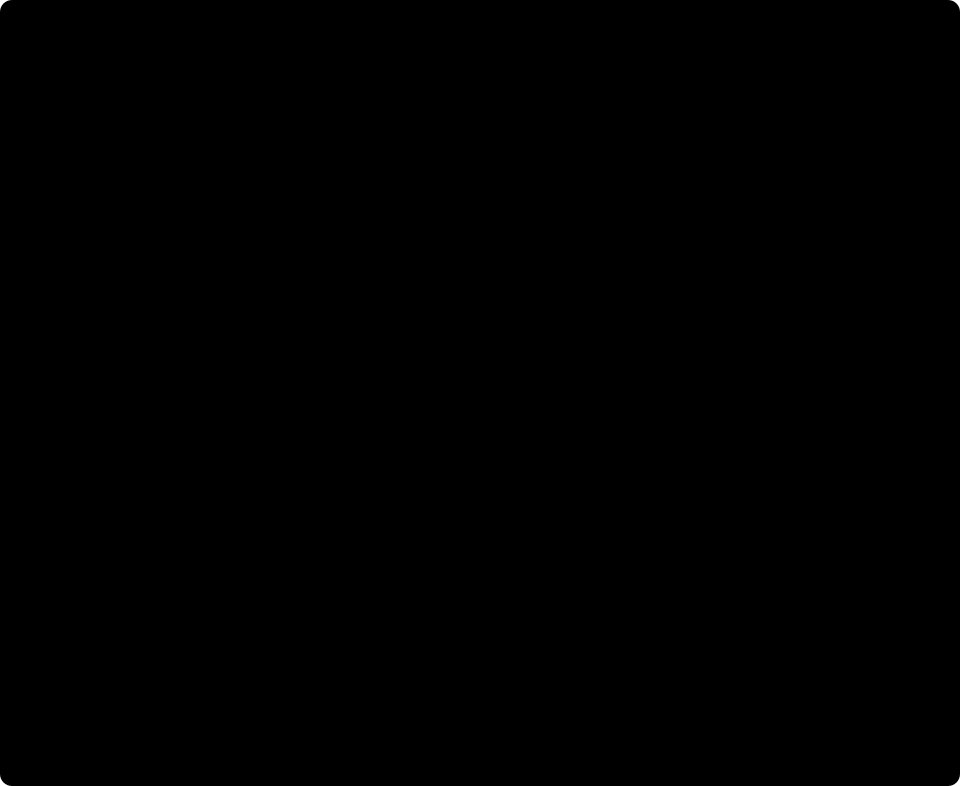

In [14]:
display(SVG(filename=str(CHART_PATH)))

## 7. Interpretation

- Live inference is classical. The RBF SVM was chosen as the served model before test results existed, not because it scored best. On the 12 test examples it made one error (a phishing host classified as legitimate). With 12 examples, each one moves accuracy by 8.3 points, and the result comes from one domain-disjoint split with one seed, so it is not an estimate of production accuracy.
- The decision score is a margin, not a probability. Features outside the training range are clipped and reported: the model was fitted on 24 hosts, so many real hosts fall outside what it saw.
- The quantum-kernel SVM is not served live, because every prediction would need 24 kernel evaluations on the QPU. Its recorded test predictions (exact simulation, IBM hardware uncorrected and calibrated) are available only as replay, labeled as such.
- Runtimes are local medians on one machine; the hardware row uses IBM's recorded execution time. No claim of quantum advantage follows from them.

## 8. Running the service

Locally, with the pinned app dependencies (from the README):

```powershell
python -m pip install -r requirements-app.txt
python -m flask --app "app:create_app()" run --port 8000
```

With Docker. The image serves on port 8000 with Gunicorn (`gunicorn --bind 0.0.0.0:8000 --workers 2 "app:create_app()"`) as a non-root user. It contains the code, the fitted scaler, the published results, the replay, and the chart, but not the trained models, which are mounted read only. Without the mount, prediction answers `503`.

```powershell
docker build -t vigilantia .
docker run --rm -p 8000:8000 -v "${PWD}/artifacts/benchmark:/srv/vigilantia/artifacts/benchmark:ro" vigilantia
```

Then open `http://127.0.0.1:8000/`. `VIGILANTIA_RESULTS_PATH`, `VIGILANTIA_REPLAY_PATH`, and `VIGILANTIA_CHART_PATH` override the file locations.

AWS deployment (Amazon ECS Express Mode on Fargate) is a later phase: no infrastructure has been provisioned and nothing has been deployed.